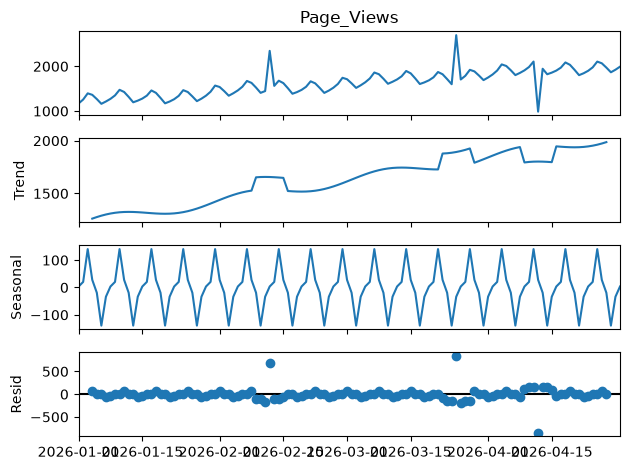

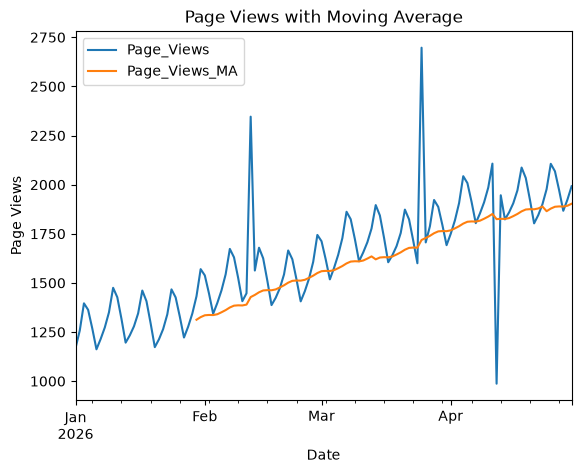

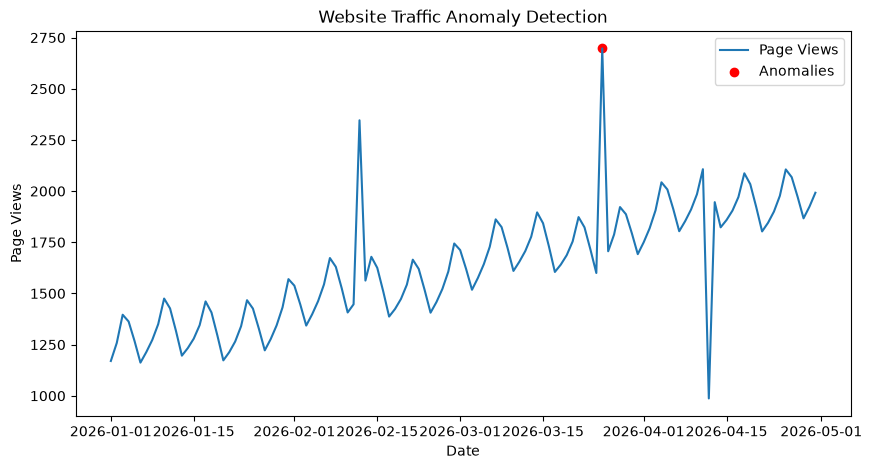

Detected Anomalies:
            Page_Views  Page_Views_Z
Date                                
2026-03-25        2697      3.759848


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Load dataset
file_path = r'D:\FDS_LAB\website_traffic.csv'
data = pd.read_csv(file_path, parse_dates=['Date'], index_col='Date')

# Time Series Decomposition
decomposition = seasonal_decompose(
    data['Page_Views'],
    model='additive',
    period=7
)
decomposition.plot()
plt.show()

# Moving Average
data['Page_Views_MA'] = data['Page_Views'].rolling(window=30).mean()

data[['Page_Views', 'Page_Views_MA']].plot()
plt.title('Page Views with Moving Average')
plt.xlabel('Date')
plt.ylabel('Page Views')
plt.show()

# Anomaly Detection using Z-score
data['Page_Views_Z'] = (
    data['Page_Views'] - data['Page_Views'].mean()
) / data['Page_Views'].std()

anomalies = data[data['Page_Views_Z'].abs() > 3]

# Plot anomalies
plt.figure(figsize=(10, 5))
plt.plot(data.index, data['Page_Views'], label='Page Views')
plt.scatter(
    anomalies.index,
    anomalies['Page_Views'],
    color='red',
    label='Anomalies'
)
plt.title('Website Traffic Anomaly Detection')
plt.xlabel('Date')
plt.ylabel('Page Views')
plt.legend()
plt.show()

# Display detected anomalies
print("Detected Anomalies:")
print(anomalies[['Page_Views', 'Page_Views_Z']])
